In [1]:
# Once from the project root, then select the .venv kernel.
# python -m venv .venv && source .venv/bin/activate && pip install -e .

# Strategy Parameter Optimization (SPO) Demonstration

This notebook presents the project’s Strategy Parameter Optimization (SPO) pipeline for momentum, trend-following, and mean-reversion strategies applied to an equal-weight basket of SPY, TLT, and GLD.

It begins with the full parameter grid to show how prices are transformed into signals, positions, and strategy returns, and then formulates parameter selection as a supervised-learning problem: 
each observation combines the market features available at a decision date, a candidate parameter set, and the candidate’s realized cumulative return over the subsequent holding period.

In a rolling walk-forward procedure, the model is trained only on prior observations whose forward returns are fully realized, predicts the performance of all available candidates, and selects the highest-scoring parameter set for the next unseen period.

The resulting out-of-sample performance is compared with historical-mean selection, fixed-parameter strategies, and the underlying market basket to assess whether conditioning parameter choices on observable market information adds value beyond simpler alternatives.

Cells call project functions and show results in memory. They do not write `output/`. Sections 1–6 follow the scripts under `script/`. From section 3&4 on, this notebook runs the full configuration and does not use the preview simplifications in those scripts. Sections 7–9 follow `main_spo.py`, `eval_spo.py`, and `plot_spo.py`.


In [2]:
from pathlib import Path

from util import load_yaml

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebook":
    PROJECT_ROOT = PROJECT_ROOT.parent

# 0. Config

Corresponds to `config.py`. This cell assigns the shared settings and the SPO settings, and omits every PWO parameter. It also loads `config/default.yaml` and `config/model.yaml`. It does not call a pipeline module. Later sections pass these names into the project functions. It passes settings forward and does not pass a data table.

Weekly sample dates provide a denser training set, while live parameter selection occurs monthly and is evaluated over the following one-month holding period.


In [3]:
CONFIG_DIR = PROJECT_ROOT / "config"

TICKERS: list[str] = ["SPY", "TLT", "GLD"]  # "SPY" | "TLT" | "GLD"
START: str = "2014-12-31"
# yfinance end is exclusive. None downloads through the latest bar.
END: str | None = "2026-09-30"  # "YYYY-MM-DD" | None

CACHE_DIR: Path = PROJECT_ROOT / "data"
CACHE_FORMAT: str = "parquet"  # "parquet" | "csv"
OUTPUT_DIR: Path = PROJECT_ROOT / "output"
PRICE_COL: str = "adj_close"
PREVIEW_ROWS: int = 10

# Fit window, training-row frequency, live rebalance, and label length.
# train_window, sample_freq, rebalance_freq, label_horizon: "1y" | "6m" | "3m" | "1m" | "1w" | "1d"
WALKFORWARD: dict[str, str] = {
    "mode": "rolling",  # "rolling" | "expanding"
    "train_window": "2y",
    "sample_freq": "1w",
    "rebalance_freq": "1m",
    "label_horizon": "1m",
    "first_decision_date": "2017-01-01",  # "YYYY-MM-DD"
}

# Production path. This notebook does not write it.
SELECTIONS_CSV: Path = OUTPUT_DIR / "spo_sel.csv"
# None is equal weight across TICKERS.
WEIGHTS: dict[str, float] | None = None  # None | dict[str, float]

STRATEGY_RUN: str | list[str] = ["momentum", "trend", "mean_reversion"]  # "momentum" | "trend" | "mean_reversion"
# long_short: raw signal; long_only: drop shorts; market_overlay: 1 + scale * signal.
POSITION_RUN: str | list[str] = ["long_short", "long_only", "market_overlay"]  # "long_short" | "long_only" | "market_overlay"
POSITION_OVERLAY_SCALE: float = 1.0

# Fixed baseline uses the first value of each list.
CANDIDATE: dict[str, dict[str, list]] = {
    "momentum": {
        "lookback": [10, 20, 40, 60],
    },
    "trend": {
        "ma_window": [20, 50, 100, 200],
    },
    "mean_reversion": {
        "lookback": [10, 20, 40],
        "entry_z": [0.5, 1.0, 1.5],
    },
}

MODEL_RUN: str | list[str] = ["hgb", "ridge", "rf"]  # "hgb" | "ridge" | "rf"
# Also build non-ML hist_mean rows in memory.
HIST_MEAN_RUN: bool = True  # True | False

# Feature windows and dataset recipe.
default_cfg = load_yaml(CONFIG_DIR / "default.yaml")
# Estimator hyperparameters.
model_cfg = load_yaml(CONFIG_DIR / "model.yaml")


# 1. Data

Corresponds to `script/run_1_data.py`. Calls `data.load_etf_panel` and `data.describe_panel`. It downloads the daily ETF panel for `TICKERS` from yfinance and displays the panel and its summary. It does not read or write cache. It passes `panel` to later sections.

Features, strategies, and labels use adjusted closing prices. Each daily observation is treated as available after that session, so realized returns following a decision begin strictly after the decision date.


In [4]:
from data import describe_panel, load_etf_panel

In [5]:
panel = load_etf_panel(
    tickers=TICKERS,
    start=START,
    end=END,
)

In [6]:
panel

Price,timestamp,asset_id,open,high,low,close,adj_close,volume,availability_time
0,2014-12-31,GLD,114.889999,115.000000,113.279999,113.580002,113.580002,7624200,2014-12-31
1,2014-12-31,SPY,207.990005,208.190002,205.389999,205.539993,169.358124,130333800,2014-12-31
2,2014-12-31,TLT,125.699997,126.169998,125.650002,125.919998,90.924278,4993300,2014-12-31
3,2015-01-02,GLD,112.489998,114.800003,112.320000,114.080002,114.080002,7109600,2015-01-02
4,2015-01-02,SPY,206.380005,206.880005,204.179993,205.429993,169.267517,121465900,2015-01-02
...,...,...,...,...,...,...,...,...,...
8854,2026-09-28,SPY,768.349976,769.539978,763.719971,765.609985,765.609985,42694500,2026-09-28
8855,2026-09-28,TLT,78.650002,78.870003,78.269997,78.620003,78.620003,63463400,2026-09-28
8856,2026-09-29,GLD,380.940002,383.000000,379.720001,382.890015,382.890015,8122800,2026-09-29
8857,2026-09-29,SPY,766.830017,766.979980,762.349976,764.200012,764.200012,36910500,2026-09-29


In [7]:
describe_panel(panel)

,dtype,count,mean,min,25%,50%,75%,max,std
Price,,,,,,,,,
timestamp,datetime64[s],8859,2020-11-12,2014-12-31,2017-12-05,2020-11-10,2023-10-18,2026-09-29,NaN
open,float64,8859.0,227.97556,78.519997,121.190002,165.309998,287.294998,778.539978,152.833261
high,float64,8859.0,229.112368,78.519997,121.589996,166.190002,288.830002,779.369995,153.660364
low,float64,8859.0,226.740666,77.839996,120.744999,164.550003,285.579987,775.429993,151.876346
close,float64,8859.0,227.992452,78.230003,121.155003,165.350006,287.550003,777.880005,152.851963
adj_close,float64,8859.0,213.088016,73.126778,103.836731,161.848572,259.960312,775.953186,152.806635
volume,int64,8859.0,37540942.183091,1436500.0,7857000.0,15894100.0,59174100.0,507244300.0,42886872.574632
availability_time,datetime64[s],8859,2020-11-12,2014-12-31,2017-12-05,2020-11-10,2023-10-18,2026-09-29,NaN


# 2. Features

Corresponds to `script/run_spo_2_feature.py`. Calls `feature.build_features`. It builds point-in-time features from the section 1 panel using the windows in `default_cfg`. The preview script may then standardize on all non-null rows. This notebook does not: model training standardizes each rolling train window on its own. It takes `panel` and passes `features` forward.

Features are calculated separately for each ETF. At each sample date, the dataset builder takes the latest complete vector available on or before that date and aggregates it across SPY, TLT, and GLD; with `WEIGHTS=None`, this aggregation is equal weighted. Incomplete warm-up rows are excluded.


In [8]:
from feature import build_features

In [9]:
feature_cfg = default_cfg.get("feature", {})

features = build_features(
    panel,
    price_col=PRICE_COL,
    windows=feature_cfg.get("windows"),
)

In [10]:
features

,timestamp,asset_id,availability_time,ret_1,ret_5,ret_21,vol_21,ma_gap_21
0,2014-12-31,GLD,2014-12-31,NaN,NaN,NaN,NaN,NaN
1,2014-12-31,SPY,2014-12-31,NaN,NaN,NaN,NaN,NaN
2,2014-12-31,TLT,2014-12-31,NaN,NaN,NaN,NaN,NaN
3,2015-01-02,GLD,2015-01-02,0.004402,NaN,NaN,NaN,NaN
4,2015-01-02,SPY,2015-01-02,-0.000535,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
8854,2026-09-28,SPY,2026-09-28,-0.007441,-0.010200,-0.004654,0.006832,0.001974
8855,2026-09-28,TLT,2026-09-28,-0.008825,-0.038875,-0.050628,0.006377,-0.031869
8856,2026-09-29,GLD,2026-09-29,0.013178,-0.042942,-0.063587,0.015394,-0.035730
8857,2026-09-29,SPY,2026-09-29,-0.001842,-0.011870,-0.004227,0.006826,0.000331


In [11]:
describe_panel(features, with_dtype=False)

,count,mean,min,25%,50%,75%,max,std
timestamp,8859,2020-11-12,2014-12-31,2017-12-05,2020-11-10,2023-10-18,2026-09-29,NaN
availability_time,8859,2020-11-12,2014-12-31,2017-12-05,2020-11-10,2023-10-18,2026-09-29,NaN
ret_1,8856.0,0.000343,-0.109423,-0.004794,0.000538,0.005642,0.105019,0.010226
ret_5,8844.0,0.001688,-0.179693,-0.010068,0.002344,0.013763,0.173582,0.021534
ret_21,8796.0,0.007024,-0.327513,-0.017868,0.007182,0.032362,0.25185,0.042807
vol_21,8796.0,0.009092,0.002155,0.006264,0.008055,0.010592,0.058565,0.004762
ma_gap_21,8799.0,0.002987,-0.205524,-0.010536,0.004019,0.017221,0.155307,0.023908


# 3&4. Candidates and strategies

Corresponds to `script/run_spo_4_candidate.py` and `script/run_spo_3_strategy.py`. Calls `strategy.select_candidate_cfg`, `candidate.build_candidates`, `candidate.iter_candidate_params`, and `strategy.run_strategies`. It first expands every parameter combination in `STRATEGY_RUN` into the candidate table. The preview strategy script keeps only the first value of each `CANDIDATE` list. This notebook does not use that simplification: it then runs every candidate on the section 1 panel and returns positions and strategy returns. It takes `panel` and passes `strategy_panel` forward. `candidates` is displayed here and is not an input to later sections.

Strategy returns use the previous observation's position, so a signal observed at time $t$ is not applied to the return already realized at $t$. The dataset later evaluates each candidate under all configured position modes; the fixed-parameter baseline uses the first value in each candidate list.


In [12]:
import pandas as pd

from candidate import build_candidates, iter_candidate_params
from strategy import run_strategies, select_candidate_cfg

In [13]:
candidate_cfg = select_candidate_cfg(CANDIDATE, STRATEGY_RUN)
candidates = build_candidates(candidate_cfg)

frames = []
for strategy_id, candidate_id, params in iter_candidate_params(candidates):
    frame = run_strategies(panel, {"price_col": PRICE_COL, strategy_id: params})
    frames.append(frame.assign(candidate_id=candidate_id, **params))
strategy_panel = pd.concat(frames, ignore_index=True)

In [14]:
candidates

,strategy_id,candidate_id,lookback,ma_window,entry_z
0,momentum,momentum_000,10,<NA>,NaN
1,momentum,momentum_001,20,<NA>,NaN
2,momentum,momentum_002,40,<NA>,NaN
3,momentum,momentum_003,60,<NA>,NaN
4,trend,trend_000,<NA>,20,NaN
5,trend,trend_001,<NA>,50,NaN
6,trend,trend_002,<NA>,100,NaN
7,trend,trend_003,<NA>,200,NaN
8,mean_reversion,mean_reversion_000,10,<NA>,0.5
9,mean_reversion,mean_reversion_001,10,<NA>,1.0


In [15]:
strategy_panel

,timestamp,asset_id,strategy_id,position,asset_return,strategy_return,candidate_id,lookback,ma_window,entry_z
0,2014-12-31,GLD,momentum,0.0,NaN,NaN,momentum_000,10.0,NaN,NaN
1,2014-12-31,SPY,momentum,0.0,NaN,NaN,momentum_000,10.0,NaN,NaN
2,2014-12-31,TLT,momentum,0.0,NaN,NaN,momentum_000,10.0,NaN,NaN
3,2015-01-02,GLD,momentum,0.0,0.004402,0.000000,momentum_000,10.0,NaN,NaN
4,2015-01-02,SPY,momentum,0.0,-0.000535,-0.000000,momentum_000,10.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
150598,2026-09-28,SPY,mean_reversion,0.0,-0.007441,-0.000000,mean_reversion_008,40.0,NaN,1.5
150599,2026-09-28,TLT,mean_reversion,1.0,-0.008825,-0.008825,mean_reversion_008,40.0,NaN,1.5
150600,2026-09-29,GLD,mean_reversion,1.0,0.013178,0.013178,mean_reversion_008,40.0,NaN,1.5
150601,2026-09-29,SPY,mean_reversion,0.0,-0.001842,-0.000000,mean_reversion_008,40.0,NaN,1.5


In [16]:
describe_panel(strategy_panel, with_dtype=False)

,count,mean,min,25%,50%,75%,max,std
timestamp,150603,2020-11-12,2014-12-31,2017-12-05,2020-11-10,2023-10-18,2026-09-29,NaN
position,150603.0,0.042356,-1.0,-1.0,0.0,1.0,1.0,0.865624
asset_return,150552.0,0.000343,-0.109423,-0.004794,0.000538,0.005642,0.105019,0.010225
strategy_return,150552.0,0.000045,-0.109423,-0.003054,0.0,0.003265,0.109423,0.008964
lookback,115167.0,26.153846,10.0,10.0,20.0,40.0,60.0,15.461414
ma_window,35436.0,92.5,20.0,42.5,75.0,125.0,200.0,68.329216
entry_z,79731.0,1.0,0.5,0.5,1.0,1.5,1.5,0.408251


# 5. Dataset

Corresponds to `script/run_spo_5_dataset.py`. Calls `dataset.build_spo_training_table` and `model.run_spo_hist_mean_selection`. It builds one training row for each sample date, position mode, and candidate from section 3&4: market features, parameter values, and the realized cumulative return over the following hold. The preview script uses only the first `POSITION_RUN` mode. This notebook does not use that simplification: it uses every mode in `POSITION_RUN`, then selects the candidate with the highest historical mean at each decision date. It takes `panel`, `features`, and `strategy_panel`, and passes `spo_training_table` to section 6. `hist_mean_selections` is passed to section 7.

Training keeps `spo_training_table`. For each strategy and position mode, a row is used only when its `decision_date` is earlier than the live decision and its `label_end` is no later than that decision, inside the rolling train window. The inputs are `ret_1`, `ret_5`, `ret_21`, `vol_21`, `ma_gap_21`, `lookback`, `ma_window`, and `entry_z`; unused parameter entries are filled with 0. The target is `label`. `decision_date`, `label_end`, `strategy_id`, and `position_mode` only choose those rows. `is_model_decision` marks live selection dates. `candidate_id` names the selected row, and historical-mean selection averages `label` by that id. `train_start` and `label_n_days` are not read.

The target `label` is the candidate's cumulative return over `(decision_date, label_end]`. It is a per-candidate forward training outcome, not the annualized return or Sharpe ratio reported in the final evaluation.


In [17]:
from dataset import build_spo_training_table
from model import run_spo_hist_mean_selection

In [18]:
spo_training_table = build_spo_training_table(
    panel,
    candidate_cfg=candidate_cfg,
    feature_cfg=default_cfg.get("feature", {}),
    walkforward_cfg=WALKFORWARD,
    dataset_cfg=default_cfg.get("dataset", {}),
    price_col=PRICE_COL,
    tickers=TICKERS,
    weights=WEIGHTS,
    position_modes=POSITION_RUN,
    overlay_scale=POSITION_OVERLAY_SCALE,
    features=features,
    strategy_panel=strategy_panel,
    show_progress=True,
)
hist_mean_selections = run_spo_hist_mean_selection(
    spo_training_table,
    walkforward_cfg=WALKFORWARD,
    min_train_rows=int(model_cfg.get("min_train_rows", 3)),
    show_progress=True,
)

dataset                             :   0%|          |     0/36210 [00:00<?, ?it/s]

spo_hist_mean                       :   0%|          |    0/1044 [00:00<?, ?it/s]

In [19]:
spo_training_table

,decision_date,label_end,train_start,is_model_decision,position_mode,strategy_id,candidate_id,lookback,ma_window,entry_z,ret_1,ret_5,ret_21,vol_21,ma_gap_21,label,label_n_days
0,2015-02-05,2015-03-05,2013-02-05,False,long_only,mean_reversion,mean_reversion_000,10,<NA>,0.5,0.000281,0.004064,0.028711,0.011206,0.005548,-0.031479,19
1,2015-02-05,2015-03-05,2013-02-05,False,long_only,mean_reversion,mean_reversion_001,10,<NA>,1.0,0.000281,0.004064,0.028711,0.011206,0.005548,-0.016035,19
2,2015-02-05,2015-03-05,2013-02-05,False,long_only,mean_reversion,mean_reversion_002,10,<NA>,1.5,0.000281,0.004064,0.028711,0.011206,0.005548,-0.000902,19
3,2015-02-05,2015-03-05,2013-02-05,False,long_only,mean_reversion,mean_reversion_003,20,<NA>,0.5,0.000281,0.004064,0.028711,0.011206,0.005548,-0.012206,19
4,2015-02-05,2015-03-05,2013-02-05,False,long_only,mean_reversion,mean_reversion_004,20,<NA>,1.0,0.000281,0.004064,0.028711,0.011206,0.005548,-0.014624,19
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35950,2026-08-27,2026-09-27,2024-08-27,False,market_overlay,momentum,momentum_003,60,<NA>,NaN,0.002517,0.012805,0.067781,0.009931,0.021895,-0.030001,20
35951,2026-08-27,2026-09-27,2024-08-27,False,market_overlay,trend,trend_000,<NA>,20,NaN,0.002517,0.012805,0.067781,0.009931,0.021895,-0.068324,20
35952,2026-08-27,2026-09-27,2024-08-27,False,market_overlay,trend,trend_001,<NA>,50,NaN,0.002517,0.012805,0.067781,0.009931,0.021895,-0.065729,20
35953,2026-08-27,2026-09-27,2024-08-27,False,market_overlay,trend,trend_002,<NA>,100,NaN,0.002517,0.012805,0.067781,0.009931,0.021895,-0.063903,20


In [20]:
describe_panel(spo_training_table, with_dtype=False)

,count,mean,min,25%,50%,75%,max,std
decision_date,35955,2021-01-03,2015-02-05,2018-03-29,2021-01-07,2023-11-02,2026-08-27,NaN
label_end,35955,2021-02-03,2015-03-05,2018-04-29,2021-02-07,2023-12-02,2026-09-27,NaN
train_start,35955,2019-01-04,2013-02-05,2016-03-29,2019-01-07,2021-11-02,2024-08-27,NaN
entry_z,19035.0,1.0,0.5,0.5,1.0,1.5,1.5,0.408259
ret_1,35955.0,0.000232,-0.043123,-0.00332,0.00043,0.003914,0.041291,0.00652
ret_5,35955.0,0.001932,-0.082573,-0.006336,0.002701,0.010097,0.101363,0.014053
ret_21,35955.0,0.007708,-0.119777,-0.007544,0.008521,0.024964,0.116802,0.028389
vol_21,35955.0,0.00907,0.004011,0.006908,0.00836,0.010508,0.040081,0.003769
ma_gap_21,35955.0,0.003255,-0.097999,-0.006005,0.003854,0.012947,0.063551,0.015903
label,35955.0,0.004107,-0.195593,-0.008145,0.003346,0.016093,0.264816,0.025821


In [21]:
hist_mean_selections

,decision_date,model_id,position_mode,strategy_id,candidate_id,lookback,ma_window,entry_z,predicted_label,realized_label,train_rows
0,2017-01-01,hist_mean,long_only,mean_reversion,mean_reversion_000,10,<NA>,0.5,0.003782,0.010107,864
1,2017-01-01,hist_mean,long_only,momentum,momentum_003,60,<NA>,NaN,0.002580,0.006101,384
2,2017-01-01,hist_mean,long_only,trend,trend_003,<NA>,200,NaN,0.002433,0.006101,384
3,2017-02-01,hist_mean,long_only,mean_reversion,mean_reversion_000,10,<NA>,0.5,0.003727,0.004004,909
4,2017-02-01,hist_mean,long_only,momentum,momentum_003,60,<NA>,NaN,0.002674,0.014387,404
...,...,...,...,...,...,...,...,...,...,...,...
1039,2026-07-01,hist_mean,market_overlay,momentum,momentum_003,60,<NA>,NaN,0.023107,0.001270,484
1040,2026-07-01,hist_mean,market_overlay,trend,trend_002,<NA>,100,NaN,0.022836,0.001270,484
1041,2026-08-01,hist_mean,market_overlay,mean_reversion,mean_reversion_002,10,<NA>,1.5,0.016329,0.017860,1089
1042,2026-08-01,hist_mean,market_overlay,momentum,momentum_003,60,<NA>,NaN,0.021095,0.004500,484


# 6. Models

Corresponds to `script/run_spo_6_model.py`. Calls `model.run_spo_walkforward_selection`. On `spo_training_table`, each model is trained only on earlier rows whose labels are fully realized, scores every candidate, and keeps the highest score for each decision date, position mode, and strategy. The preview script uses the first `POSITION_RUN` mode and the first `MODEL_RUN` model. This notebook does not use that simplification: it uses the full `spo_training_table` and every model in `MODEL_RUN`. It takes `spo_training_table` and passes `spo_selections` forward.

Candidates are ranked within each decision date, so relative scores determine the choice even when absolute predictions are imperfect. Standardization is fitted separately on each rolling training fold.


In [22]:
from model import run_spo_walkforward_selection

In [ ]:
spo_selections = run_spo_walkforward_selection(
    spo_training_table,
    walkforward_cfg=WALKFORWARD,
    model_cfg=model_cfg,
    model_ids=MODEL_RUN,
    show_progress=True,
)

spo_model                           :   0%|          |    0/3132 [00:00<?, ?it/s]

In [24]:
spo_selections

,decision_date,model_id,position_mode,strategy_id,candidate_id,lookback,ma_window,entry_z,predicted_label,realized_label,train_rows
0,2017-01-01,hgb,long_only,mean_reversion,mean_reversion_002,10,<NA>,1.5,0.001658,0.008268,864
1,2017-01-01,hgb,long_only,momentum,momentum_003,60,<NA>,NaN,-0.010668,0.006101,384
2,2017-01-01,hgb,long_only,trend,trend_003,<NA>,200,NaN,-0.014739,0.006101,384
3,2017-02-01,hgb,long_only,mean_reversion,mean_reversion_000,10,<NA>,0.5,0.003444,0.004004,909
4,2017-02-01,hgb,long_only,momentum,momentum_003,60,<NA>,NaN,-0.001633,0.014387,404
...,...,...,...,...,...,...,...,...,...,...,...
3127,2026-07-01,ridge,market_overlay,momentum,momentum_003,60,<NA>,NaN,0.021195,0.001270,484
3128,2026-07-01,ridge,market_overlay,trend,trend_003,<NA>,200,NaN,0.021701,0.001270,484
3129,2026-08-01,ridge,market_overlay,mean_reversion,mean_reversion_002,10,<NA>,1.5,0.021865,0.017860,1089
3130,2026-08-01,ridge,market_overlay,momentum,momentum_003,60,<NA>,NaN,0.030000,0.004500,484


# 7. Selections

Corresponds to `main_spo.py`. It does not reload prices, rebuild `spo_training_table`, or fit models again. When `HIST_MEAN_RUN` is true, it stacks `spo_selections` and `hist_mean_selections` into the selection table that `main_spo.py` writes to `spo_sel.csv`. This notebook does not write that file. It takes those two tables and passes `spo_sel` forward.

`predicted_label` is available when the decision is made and determines the selected candidate; `realized_label` becomes known only after the holding period and is retained for out-of-sample evaluation.


In [25]:
import pandas as pd

In [26]:
frames = [spo_selections, hist_mean_selections] if HIST_MEAN_RUN else [spo_selections]
spo_sel = pd.concat(frames, ignore_index=True).sort_values(
    ["model_id", "position_mode", "decision_date", "strategy_id"]
).reset_index(drop=True)

In [27]:
spo_sel

,decision_date,model_id,position_mode,strategy_id,candidate_id,lookback,ma_window,entry_z,predicted_label,realized_label,train_rows
0,2017-01-01,hgb,long_only,mean_reversion,mean_reversion_002,10,<NA>,1.5,0.001658,0.008268,864
1,2017-01-01,hgb,long_only,momentum,momentum_003,60,<NA>,NaN,-0.010668,0.006101,384
2,2017-01-01,hgb,long_only,trend,trend_003,<NA>,200,NaN,-0.014739,0.006101,384
3,2017-02-01,hgb,long_only,mean_reversion,mean_reversion_000,10,<NA>,0.5,0.003444,0.004004,909
4,2017-02-01,hgb,long_only,momentum,momentum_003,60,<NA>,NaN,-0.001633,0.014387,404
...,...,...,...,...,...,...,...,...,...,...,...
4171,2026-07-01,ridge,market_overlay,momentum,momentum_003,60,<NA>,NaN,0.021195,0.001270,484
4172,2026-07-01,ridge,market_overlay,trend,trend_003,<NA>,200,NaN,0.021701,0.001270,484
4173,2026-08-01,ridge,market_overlay,mean_reversion,mean_reversion_002,10,<NA>,1.5,0.021865,0.017860,1089
4174,2026-08-01,ridge,market_overlay,momentum,momentum_003,60,<NA>,NaN,0.030000,0.004500,484


In [28]:
# spo_sel.to_csv("spo_sel.csv", index=False)

# 8. Evaluation

Corresponds to `eval_spo.py`. Calls `evaluate.run_evaluation` and `evaluate.run_ml_vs_hist_mean_diagnosis`. Conditional and historical-mean picks use the realized labels already stored on `spo_sel`. The fixed-parameter baseline and the market basket are computed from `panel`. It does not write `output/`. It takes `panel` and `spo_sel`, and passes `spo_summary`, `spo_periods`, and `spo_diagnosis` forward.

All methods use the same decision dates and holding periods. Reported returns are gross of transaction costs and slippage, which are outside the scope of this demonstration.


In [29]:
from evaluate import run_evaluation, run_ml_vs_hist_mean_diagnosis

In [30]:
spo_summary, spo_periods = run_evaluation(
    panel,
    selections=spo_sel,
    walkforward_cfg=WALKFORWARD,
    candidate_cfg=candidate_cfg,
    price_col=PRICE_COL,
    tickers=TICKERS,
    weights=WEIGHTS,
    overlay_scale=POSITION_OVERLAY_SCALE,
)
spo_diagnosis = run_ml_vs_hist_mean_diagnosis(spo_sel)

In [31]:
spo_summary

,sleeve,model_id,position_mode,strategy_id,n_periods,cumulative_return,ann_return,ann_vol,sharpe,max_drawdown,hit_rate
0,baseline,,long_only,blend,116.0,0.566529,0.047529,0.054663,0.877966,-0.080502,0.663793
1,baseline,,long_only,mean_reversion,116.0,0.376524,0.033611,0.051717,0.665685,-0.114260,0.637931
2,baseline,,long_only,momentum,116.0,0.631897,0.051968,0.070708,0.752621,-0.071430,0.594828
3,baseline,,long_only,trend,116.0,0.683343,0.055352,0.069160,0.814527,-0.092168,0.568966
4,baseline,,long_short,blend,116.0,0.023911,0.002447,0.040583,0.080387,-0.138433,0.551724
...,...,...,...,...,...,...,...,...,...,...,...
56,cpo,ridge,market_overlay,blend,116.0,2.348979,0.133186,0.120005,1.106038,-0.191474,0.672414
57,cpo,ridge,market_overlay,mean_reversion,116.0,1.833994,0.113781,0.106294,1.070751,-0.199011,0.620690
58,cpo,ridge,market_overlay,momentum,116.0,2.521713,0.139097,0.133407,1.046406,-0.218589,0.646552
59,cpo,ridge,market_overlay,trend,116.0,2.616083,0.142217,0.150660,0.960960,-0.190247,0.663793


In [ ]:
# spo_summary.to_csv("spo_summary.csv", index=False)

In [33]:
spo_periods

,decision_date,label_end,model_id,position_mode,strategy_id,sleeve,period_return
0,2017-01-01,2017-02-01,,long_only,blend,baseline,0.013136
1,2017-02-01,2017-03-01,,long_only,blend,baseline,0.015794
2,2017-03-01,2017-04-01,,long_only,blend,baseline,-0.002267
3,2017-04-01,2017-05-01,,long_only,blend,baseline,0.003312
4,2017-05-01,2017-06-01,,long_only,blend,baseline,0.003787
...,...,...,...,...,...,...,...
7071,2026-04-01,2026-05-01,,,,market,0.019649
7072,2026-05-01,2026-06-01,,,,market,0.008585
7073,2026-06-01,2026-07-01,,,,market,-0.036575
7074,2026-07-01,2026-08-01,,,,market,-0.011063


In [34]:
spo_diagnosis

,model_id,position_mode,strategy_id,n_disagree,agree_rate,mean_realized_diff,ml_win_rate
0,hgb,long_only,mean_reversion,79,0.318966,0.001349,0.518987
1,hgb,long_only,momentum,45,0.612069,-0.000206,0.511111
2,hgb,long_only,trend,56,0.517241,0.002131,0.535714
3,hgb,long_short,mean_reversion,85,0.267241,-0.002391,0.458824
4,hgb,long_short,momentum,39,0.663793,-0.000368,0.538462
5,hgb,long_short,trend,56,0.517241,0.003062,0.589286
6,hgb,market_overlay,mean_reversion,79,0.318966,0.001713,0.556962
7,hgb,market_overlay,momentum,45,0.612069,-0.002476,0.444444
8,hgb,market_overlay,trend,65,0.439655,0.006759,0.584615
9,rf,long_only,mean_reversion,79,0.318966,-0.000560,0.518987


# 9. Plot

Corresponds to `plot_spo.py`. Calls `evaluate.spo_equity_figure`. It draws equity curves from `spo_periods` using that script's display filters: cpo, baseline, and market, position `market_overlay`, strategy `blend`, and every model. The filters change only the figure. It does not write a file. It takes `spo_periods` and does not pass a data table forward.

In [35]:
from evaluate import spo_equity_figure

In [ ]:
SLEEVE_IDS = ["cpo", "baseline", "market"]  # "cpo" | "baseline" | "market"
POSITION_IDS = ["market_overlay"]  # "long_short" | "long_only" | "market_overlay"
STRATEGY_IDS = ["blend"]  # "blend" | "momentum" | "trend" | "mean_reversion"
MODEL_IDS = []  # "hgb" | "ridge" | "rf" | "hist_mean"
DATE_START = None  # "YYYY-MM-DD" | None
DATE_END = None  # "YYYY-MM-DD" | None

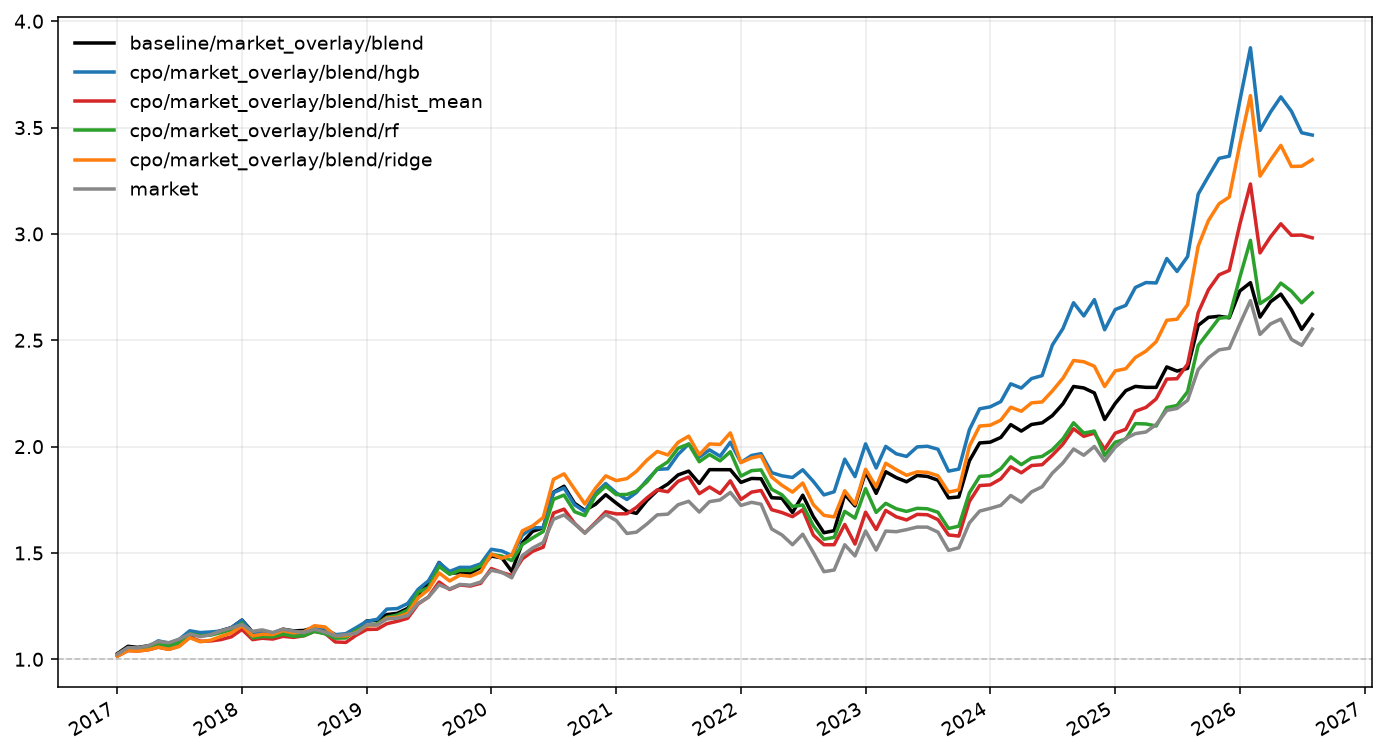

In [37]:
spo_plot = spo_equity_figure(
    spo_periods,
    sleeve_ids=SLEEVE_IDS,
    position_ids=POSITION_IDS,
    strategy_ids=STRATEGY_IDS,
    model_ids=MODEL_IDS,
    date_start=DATE_START,
    date_end=DATE_END,
)

In [ ]:
# spo_plot.savefig("spo_plot.png")